# Customer Lifetime Value & Segmentation Engine
**Machine Learning · Final Project · Retail & Marketing**

## 1. Problem framing
- **Who has the problem?** The marketing team of an online gift retailer that treats every customer the same.
- **Decision supported:** who to reward, who to win back, and how much to spend on each group.
- **Two ML tasks:**
  1. **Segmentation (unsupervised):** group customers by RFM behaviour (Recency, Frequency, Monetary) with K-Means and compare with Hierarchical clustering.
  2. **Regression (supervised):** predict each customer's **spending in the next 90 days** (`Future90DaySpending`). The target is built with a **time cut-off**, so no future information leaks into the features.
- **Metrics and why:**
  - **MAE (primary)**: average error in GBP, easy for managers to read and less dominated by a few huge wholesale customers than RMSE.
  - **RMSE and R²**: secondary, they show how badly we miss on large spenders.
  - **Top-10% capture** (business metric): share of all future revenue found in the 10% of customers the model ranks highest. Random targeting gives about 10%.
  - **Silhouette score**: quality of the segmentation.
- **Scope note:** 90-day spend is a short-horizon proxy for customer lifetime value, not a full CLV model.

## 2. Imports and settings

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
RANDOM_STATE = 42
print('Libraries loaded | scikit-learn', sklearn.__version__)

Libraries loaded | scikit-learn 1.7.2


## 3. Data understanding
**Source:** *Online Retail II* (UCI), https://archive.ics.uci.edu/dataset/502/online+retail+ii  
Download `online_retail_II.xlsx` and put it next to this notebook (do not commit it to GitHub, it is large).  
The file has **two worksheets** (Dec 2009 to Dec 2010 and Dec 2010 to Dec 2011). We read both and combine them. The two sheets overlap for the first days of December 2010, so exact duplicate rows are removed in the cleaning step.

Each row is one **invoice line** (not one customer and not one invoice). There is no class label, so class balance does not apply; we inspect the target distribution instead.

In [2]:
DATA_PATH = 'online_retail_II.xlsx'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError('Put online_retail_II.xlsx next to this notebook. '
                            'Source: https://archive.ics.uci.edu/dataset/502/online+retail+ii')

sheets = pd.read_excel(DATA_PATH, sheet_name=None)   # reading both sheets can take a few minutes
print({name: frame.shape for name, frame in sheets.items()})
df = pd.concat(sheets.values(), ignore_index=True)
print('Combined raw shape:', df.shape)
display(df.head())

{'Year 2009-2010': (525461, 8), 'Year 2010-2011': (541910, 8)}
Combined raw shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
descriptions = {
    'Invoice': 'Invoice number (starts with C for a cancellation/return)',
    'StockCode': 'Product code',
    'Description': 'Product name',
    'Quantity': 'Units per invoice line (negative for returns)',
    'InvoiceDate': 'Invoice date and time',
    'Price': 'Unit price in GBP',
    'Customer ID': 'Customer identifier',
    'Country': 'Customer country',
}
data_dictionary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_%': df.isna().mean().mul(100).round(2),
    'unique': df.nunique(),
    'meaning': pd.Series(descriptions),
})
display(data_dictionary)
display(df[['Quantity', 'Price']].describe())

is_cancel = df['Invoice'].astype(str).str.upper().str.startswith('C')
print('Date range:', df['InvoiceDate'].min(), 'to', df['InvoiceDate'].max())
print(f'Cancellation lines: {is_cancel.sum():,} ({is_cancel.mean():.1%} of rows)')
print(f'Lines with Quantity <= 0: {(df.Quantity <= 0).sum():,} | Price <= 0: {(df.Price <= 0).sum():,}')
print(f'Lines with missing Customer ID: {df["Customer ID"].isna().sum():,} ({df["Customer ID"].isna().mean():.1%})')

,dtype,missing,missing_%,unique,meaning
Invoice,object,0,0.00,53628,Invoice number (starts with C for a cancellati...
StockCode,object,0,0.00,5305,Product code
Description,object,4382,0.41,5698,Product name
Quantity,int64,0,0.00,1057,Units per invoice line (negative for returns)
InvoiceDate,datetime64[ns],0,0.00,47635,Invoice date and time
Price,float64,0,0.00,2807,Unit price in GBP
Customer ID,float64,243007,22.77,5942,Customer identifier
Country,object,0,0.00,43,Customer country


,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Cancellation lines: 19,494 (1.8% of rows)
Lines with Quantity <= 0: 22,950 | Price <= 0: 6,207
Lines with missing Customer ID: 243,007 (22.8%)


## 4. Data cleaning
Heavy cleaning is needed, and every step is logged so we can see how many rows each rule removes:
- **Exact duplicates** (includes the overlap between the two sheets).
- **Missing Customer ID**: customer-level modelling is impossible without an ID.
- **Cancellations and returns** (invoice starts with `C`, negative quantity).
- **Non-positive quantity or price** (adjustments, bad-debt entries).
- **Non-product stock codes** such as `POST`, `DOT`, `M`, `BANK CHARGES`: they are fees, not purchases. Real product codes start with 5 digits.

We do **not** remove high-spending customers: they are legitimate wholesale buyers and matter to the business. Their effect is handled by log transforms and checked in the error analysis.

In [4]:
steps = []
def record(label, frame):
    prev = steps[-1]['Rows_after'] if steps else len(frame)
    steps.append({'Step': label, 'Rows_after': len(frame), 'Rows_removed': prev - len(frame)})
    return frame

d = record('Raw data (both sheets)', df)
d = record('Drop exact duplicate rows', d.drop_duplicates())
d = record('Drop rows without Customer ID', d.dropna(subset=['Customer ID']))
d = record('Drop cancellations / returns (Invoice starts with C)',
           d[~d['Invoice'].astype(str).str.upper().str.startswith('C')])
d = record('Keep only Quantity > 0 and Price > 0', d[(d['Quantity'] > 0) & (d['Price'] > 0)])
d = record('Drop non-product stock codes (POST, DOT, M, BANK CHARGES, ...)',
           d[d['StockCode'].astype(str).str.match(r'^\d{5}')])

df_clean = d.copy()
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int).astype(str)
df_clean['Invoice'] = df_clean['Invoice'].astype(str)
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']

display(pd.DataFrame(steps))
print('Clean shape:', df_clean.shape)
print('Unique customers:', df_clean['Customer ID'].nunique())
print('Unique invoices:', df_clean['Invoice'].nunique())
print('Total revenue (GBP):', round(df_clean['TotalPrice'].sum(), 2))
print('Missing values in key columns after cleaning:',
      int(df_clean[['Invoice', 'StockCode', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']].isna().sum().sum()))

,Step,Rows_after,Rows_removed
0,Raw data (both sheets),1067371,0
1,Drop exact duplicate rows,1033036,34335
2,Drop rows without Customer ID,797885,235151
3,Drop cancellations / returns (Invoice starts w...,779495,18390
4,Keep only Quantity > 0 and Price > 0,779425,70
5,"Drop non-product stock codes (POST, DOT, M, BA...",776577,2848


Clean shape: (776577, 9)
Unique customers: 5852
Unique invoices: 36594
Total revenue (GBP): 17068567.97
Missing values in key columns after cleaning: 0


## 5. Exploratory data analysis (EDA)
We look at one variable at a time (**univariate**), pairs of variables (**bivariate**) and several variables together (**multivariate**). The EDA uses the whole clean history for description only; nothing from this section is used to train a model.

In [5]:
# Customer-level table for EDA (whole period, description only)
last_date = df_clean['InvoiceDate'].max()
eda = df_clean.groupby('Customer ID').agg(
    last_purchase=('InvoiceDate', 'max'), first_purchase=('InvoiceDate', 'min'),
    Frequency=('Invoice', 'nunique'), Monetary=('TotalPrice', 'sum')).reset_index()
eda['Recency'] = (last_date - eda['last_purchase']).dt.days
eda['AvgOrderValue'] = eda['Monetary'] / eda['Frequency']
eda['Tenure'] = (last_date - eda['first_purchase']).dt.days
display(eda[['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'Tenure']].describe())

,Recency,Frequency,Monetary,AvgOrderValue,Tenure
count,"5,852.00","5,852.00","5,852.00","5,852.00","5,852.00"
mean,199.20,6.25,"2,916.71",384.40,472.99
std,208.51,12.75,"14,306.85","1,254.73",223.20
min,0.00,1.00,2.95,2.95,0.00
25%,24.00,1.00,339.57,176.15,311.00
50%,94.00,3.00,856.02,277.87,528.00
75%,378.00,7.00,"2,241.03",410.56,666.00
max,738.00,373.00,"580,987.04","84,236.25",738.00


### 5.1 Univariate analysis

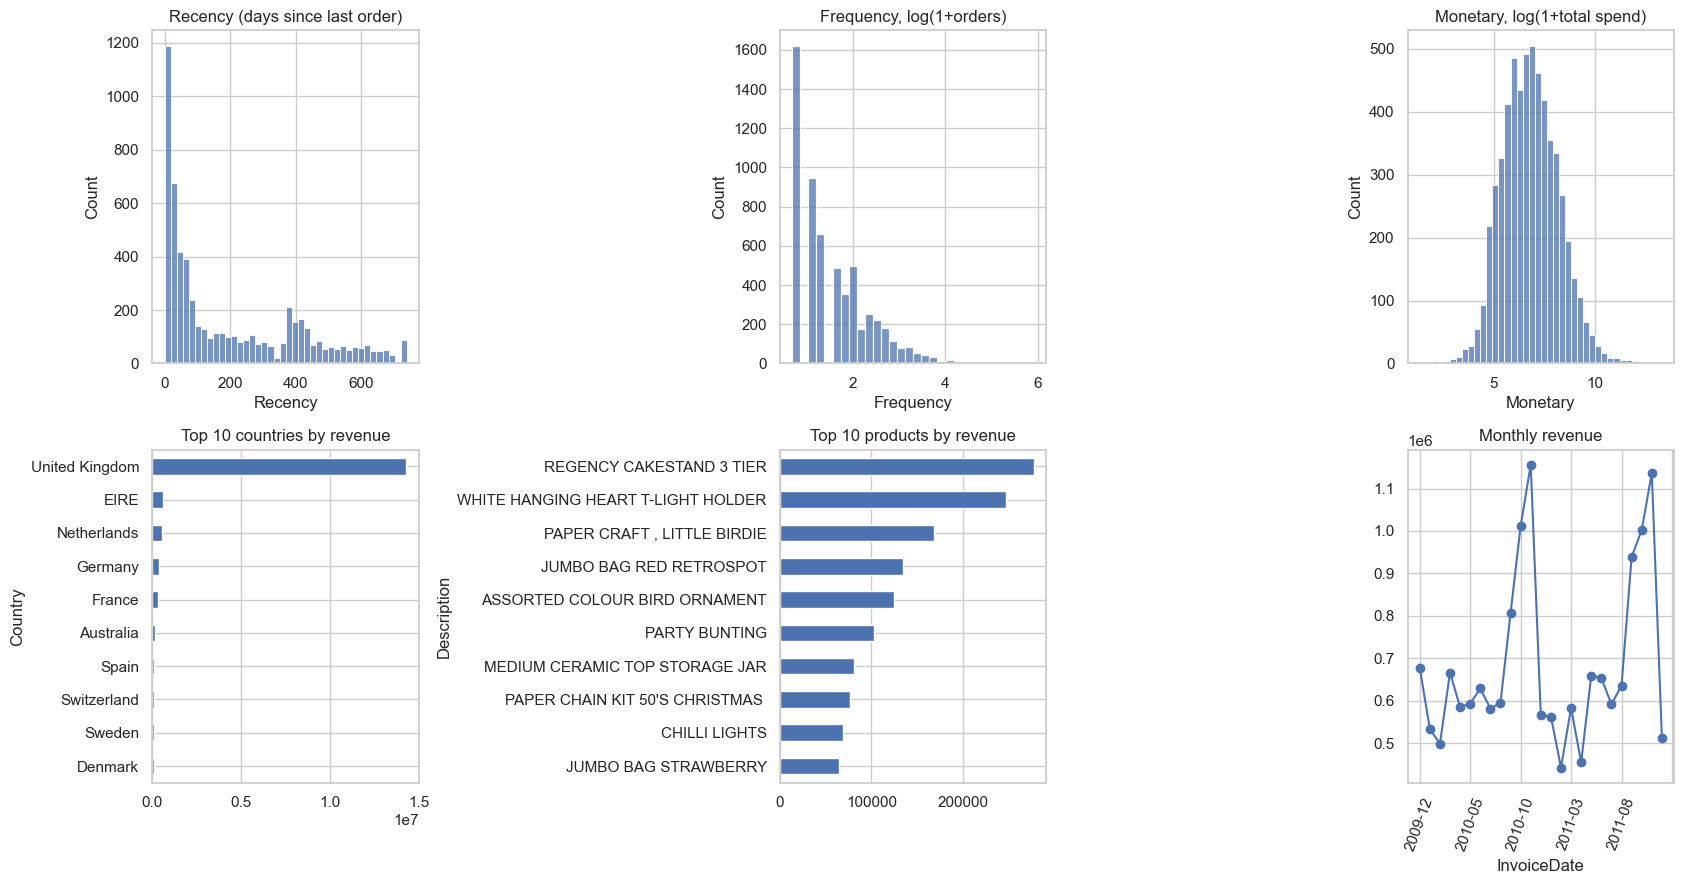

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(eda['Recency'], bins=40, ax=axes[0, 0]); axes[0, 0].set_title('Recency (days since last order)')
sns.histplot(np.log1p(eda['Frequency']), bins=30, ax=axes[0, 1]); axes[0, 1].set_title('Frequency, log(1+orders)')
sns.histplot(np.log1p(eda['Monetary']), bins=40, ax=axes[0, 2]); axes[0, 2].set_title('Monetary, log(1+total spend)')

country = df_clean.groupby('Country')['TotalPrice'].sum().nlargest(10).sort_values()
country.plot(kind='barh', ax=axes[1, 0], title='Top 10 countries by revenue')
products = df_clean.groupby('Description')['TotalPrice'].sum().nlargest(10).sort_values()
products.plot(kind='barh', ax=axes[1, 1], title='Top 10 products by revenue')
monthly = df_clean.groupby(df_clean['InvoiceDate'].dt.to_period('M').astype(str))['TotalPrice'].sum()
monthly.plot(ax=axes[1, 2], marker='o', title='Monthly revenue'); axes[1, 2].tick_params(axis='x', rotation=70)
plt.tight_layout(); plt.show()

### 5.2 Bivariate analysis

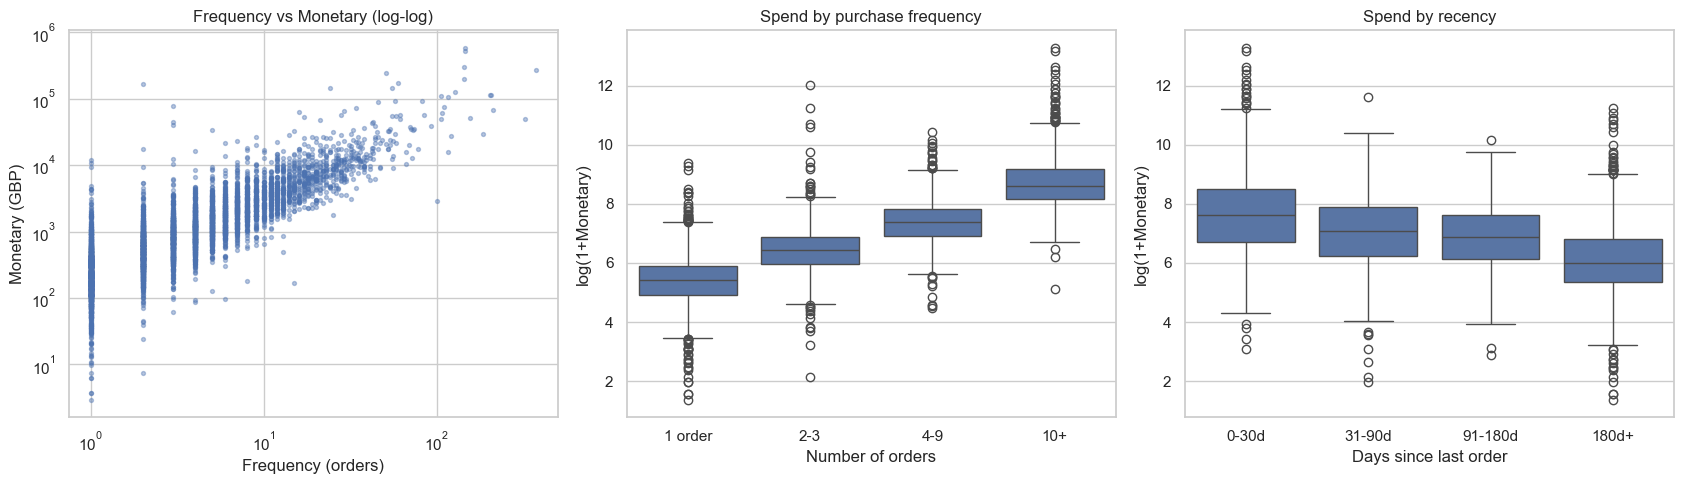

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(eda['Frequency'], eda['Monetary'], s=8, alpha=.4)
axes[0].set(xscale='log', yscale='log', xlabel='Frequency (orders)', ylabel='Monetary (GBP)', title='Frequency vs Monetary (log-log)')

eda['FreqGroup'] = pd.cut(eda['Frequency'], [0, 1, 3, 9, np.inf], labels=['1 order', '2-3', '4-9', '10+'])
sns.boxplot(data=eda, x='FreqGroup', y=np.log1p(eda['Monetary']), ax=axes[1])
axes[1].set(xlabel='Number of orders', ylabel='log(1+Monetary)', title='Spend by purchase frequency')

eda['RecencyGroup'] = pd.cut(eda['Recency'], [-1, 30, 90, 180, np.inf], labels=['0-30d', '31-90d', '91-180d', '180d+'])
sns.boxplot(data=eda, x='RecencyGroup', y=np.log1p(eda['Monetary']), ax=axes[2])
axes[2].set(xlabel='Days since last order', ylabel='log(1+Monetary)', title='Spend by recency')
plt.tight_layout(); plt.show()

### 5.3 Multivariate analysis

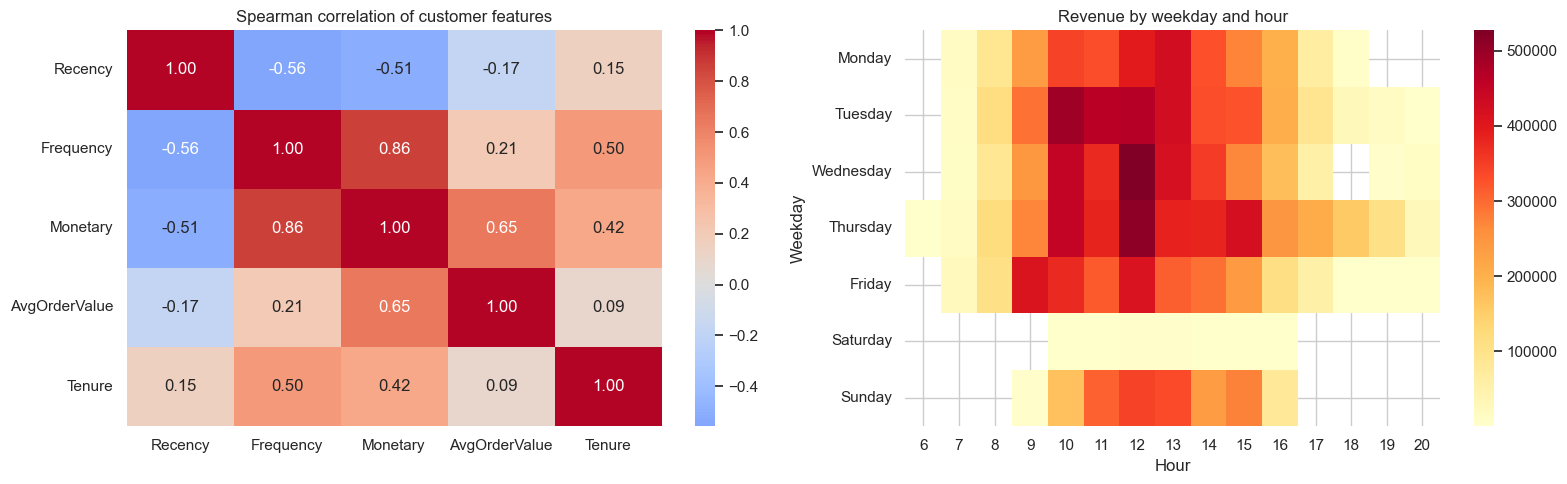

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
corr = eda[['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'Tenure']].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Spearman correlation of customer features')

tmp = df_clean.assign(Weekday=df_clean['InvoiceDate'].dt.day_name(), Hour=df_clean['InvoiceDate'].dt.hour)
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot = tmp.pivot_table(index='Weekday', columns='Hour', values='TotalPrice', aggfunc='sum').reindex(order).dropna(how='all')
sns.heatmap(pivot, cmap='YlOrRd', ax=axes[1]); axes[1].set_title('Revenue by weekday and hour')
plt.tight_layout(); plt.show()

### 5.4 EDA insights
The numbers below are computed by the code, so they always match the charts above.

In [9]:
cust_total = eda.set_index('Customer ID')['Monetary']
uk_share = df_clean.loc[df_clean['Country'].eq('United Kingdom'), 'TotalPrice'].sum() / df_clean['TotalPrice'].sum()
top10_share = cust_total.nlargest(int(np.ceil(len(cust_total) * .10))).sum() / cust_total.sum()
one_time = (eda['Frequency'] == 1).mean()
full_months = monthly.iloc[:-1]   # the last month is incomplete, so it is excluded from peak/low
peak_month, low_month = full_months.idxmax(), full_months.idxmin()
rho_fm = eda['Frequency'].corr(eda['Monetary'], method='spearman')
rho_rm = eda['Recency'].corr(eda['Monetary'], method='spearman')
top10_products = df_clean.groupby('Description')['TotalPrice'].sum().nlargest(10).sum() / df_clean['TotalPrice'].sum()

print(f'Insight 1 - Geographic concentration: the UK generates {uk_share:.1%} of revenue, so campaigns can start UK-first, but results may not generalise abroad.')
print(f'Insight 2 - Seasonality: among full months revenue peaks in {peak_month} (GBP {full_months.max():,.0f}) and is lowest in {low_month} (GBP {full_months.min():,.0f}); one 90-day window cannot represent every season.')
print(f'Insight 3 - Skewed value: the top 10% of customers bring {top10_share:.1%} of revenue; mean customer spend is GBP {cust_total.mean():,.0f} versus a median of GBP {cust_total.median():,.0f}.')
print(f'Insight 4 - Repeat behaviour: {one_time:.1%} of customers ordered only once; they are the natural target for win-back and second-order campaigns.')
stronger = 'Frequency' if abs(rho_fm) >= abs(rho_rm) else 'Recency'
print(f'Insight 5 - Drivers of value: Spearman correlation with Monetary is {rho_fm:.2f} for Frequency and {rho_rm:.2f} for Recency, so {stronger} is the stronger link to total spend.')
print(f'Extra - The top 10 products make up {top10_products:.1%} of revenue.')

Insight 1 - Geographic concentration: the UK generates 83.7% of revenue, so campaigns can start UK-first, but results may not generalise abroad.
Insight 2 - Seasonality: among full months revenue peaks in 2010-11 (GBP 1,155,978) and is lowest in 2011-02 (GBP 442,294); one 90-day window cannot represent every season.
Insight 3 - Skewed value: the top 10% of customers bring 63.9% of revenue; mean customer spend is GBP 2,917 versus a median of GBP 856.
Insight 4 - Repeat behaviour: 27.6% of customers ordered only once; they are the natural target for win-back and second-order campaigns.
Insight 5 - Drivers of value: Spearman correlation with Monetary is 0.86 for Frequency and -0.51 for Recency, so Frequency is the stronger link to total spend.
Extra - The top 10 products make up 7.9% of revenue.


**Hypotheses to test with the models (not proven effects):**
1. Because value is concentrated in few customers, large spenders will be the hardest to predict (checked in the error analysis).
2. Recent activity (spend in the last 90 days before the cut-off) should be a strong predictor of next-90-day spend (checked with permutation importance).
3. Frequency and recency together should separate loyal customers from customers about to leave (checked with the segments).

## 6. Time cut-off and feature engineering (no leakage)
To predict the **next 90 days**, we pretend to stand at a historical **cut-off date** (90 days before the last transaction in the data):
- **Features** use only transactions **before** the cut-off.
- **Target** = total spend in the **90 days after** the cut-off. Customers who did not buy get 0.
- Customers with no purchase before the cut-off cannot be scored and are excluded (new customers have no history).

One function, `build_features`, creates the features for **any** date. We use it twice: at the cut-off for training, and at the final date for the real "next 90 days" scores shown in the app.

| Feature | Meaning |
|---|---|
| Recency | days since last order |
| Frequency | number of distinct invoices |
| Monetary | total spend so far |
| AvgOrderValue | mean invoice total |
| CustomerTenure | days since first order |
| Spend_Last90d / Orders_Last90d | spend and orders in the 90 days before the date |

Cut-off date: 2011-09-10 12:50:00 | last date in data: 2011-12-09 12:50:00
Customers with history before cut-off: 5256
Customers with zero spend in the next 90 days: 56.4%


,Customer ID,Recency,Frequency,Monetary,AvgOrderValue,CustomerTenure,Spend_Last90d,Orders_Last90d,Future90DaySpending
0,12346,235,3,"77,352.96","25,784.32",556,0.00,0.00,0.00
1,12347,39,6,"3,402.39",567.06,313,584.91,1.00,"1,519.14"
2,12348,158,4,"1,388.40",347.10,347,0.00,0.00,270.00
3,12349,317,2,"2,221.14","1,110.57",498,0.00,0.00,"1,457.55"
4,12350,219,1,294.40,294.40,219,0.00,0.00,0.00


count     5,256.00
mean        569.03
std       3,983.42
min           0.00
25%           0.00
50%           0.00
75%         430.55
max     168,469.60
Name: Future90DaySpending, dtype: float64

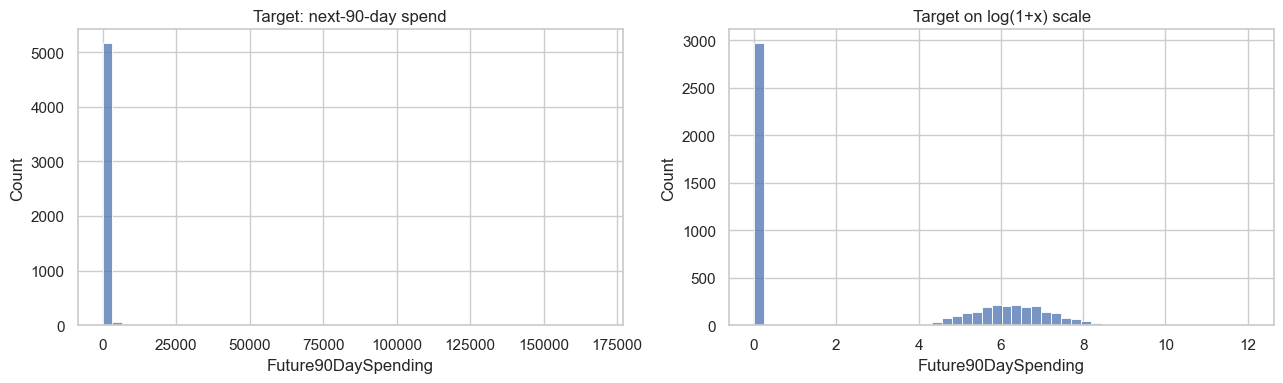

In [10]:
WINDOW = 90

def build_features(tx, as_of):
    """Customer features using only transactions strictly before `as_of`."""
    tx = tx[tx['InvoiceDate'] < as_of]
    g = tx.groupby('Customer ID').agg(first=('InvoiceDate', 'min'), last=('InvoiceDate', 'max'),
                                      Frequency=('Invoice', 'nunique'), Monetary=('TotalPrice', 'sum'))
    g['Recency'] = (as_of - g['last']).dt.days
    g['CustomerTenure'] = (as_of - g['first']).dt.days
    inv_totals = tx.groupby(['Customer ID', 'Invoice'])['TotalPrice'].sum()
    g['AvgOrderValue'] = inv_totals.groupby('Customer ID').mean()
    recent = tx[tx['InvoiceDate'] >= as_of - pd.Timedelta(days=WINDOW)]
    g['Spend_Last90d'] = recent.groupby('Customer ID')['TotalPrice'].sum()
    g['Orders_Last90d'] = recent.groupby('Customer ID')['Invoice'].nunique()
    g[['Spend_Last90d', 'Orders_Last90d']] = g[['Spend_Last90d', 'Orders_Last90d']].fillna(0)
    cols = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'CustomerTenure', 'Spend_Last90d', 'Orders_Last90d']
    return g[cols].reset_index()

FEATURES = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'CustomerTenure', 'Spend_Last90d', 'Orders_Last90d']
RFM_COLS = ['Recency', 'Frequency', 'Monetary']
TARGET = 'Future90DaySpending'

cutoff_date = df_clean['InvoiceDate'].max() - pd.Timedelta(days=WINDOW)
future = df_clean[df_clean['InvoiceDate'] >= cutoff_date]
features_at_cutoff = build_features(df_clean, cutoff_date)
future_spend = future.groupby('Customer ID')['TotalPrice'].sum().rename(TARGET).reset_index()

ml_data = features_at_cutoff.merge(future_spend, on='Customer ID', how='left', validate='one_to_one')
ml_data[TARGET] = ml_data[TARGET].fillna(0)

# Leakage checks
assert df_clean.loc[df_clean['InvoiceDate'] < cutoff_date, 'InvoiceDate'].max() < cutoff_date
assert future['InvoiceDate'].min() >= cutoff_date
assert (ml_data[FEATURES] >= 0).all().all() and ml_data[FEATURES].notna().all().all()

print('Cut-off date:', cutoff_date, '| last date in data:', df_clean['InvoiceDate'].max())
print('Customers with history before cut-off:', len(ml_data))
print(f'Customers with zero spend in the next 90 days: {(ml_data[TARGET] == 0).mean():.1%}')
display(ml_data.head())
display(ml_data[TARGET].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ml_data[TARGET], bins=50, ax=ax[0]); ax[0].set_title('Target: next-90-day spend')
sns.histplot(np.log1p(ml_data[TARGET]), bins=50, ax=ax[1]); ax[1].set_title('Target on log(1+x) scale')
plt.tight_layout(); plt.show()

## 7. Customer segmentation: K-Means vs Hierarchical clustering
Segmentation is unsupervised and is **not** used as an input of the regression, so it does not touch the supervised test set. It uses the **historical RFM** of the cut-off cohort, so the same fitted pipeline can later score customers at the final date.

- `log1p` reduces the strong skew and `StandardScaler` gives R, F and M the same weight.
- We compare **K-Means** and **Hierarchical (Ward)** clustering with the silhouette score for k = 2 to 8.
- k = 2 usually has the best silhouette but only separates "active" from "inactive", which is too coarse for marketing. We therefore choose k from **3 to 6** and explain this choice below.

,KMeans_silhouette,Hierarchical_silhouette,KMeans_inertia,Agreement_ARI
k,,,,
2,0.46,0.44,"7,688.90",0.77
3,0.36,0.38,"5,691.12",0.43
4,0.38,0.38,"4,504.28",0.42
5,0.34,0.27,"3,764.55",0.48
6,0.33,0.30,"3,323.59",0.62
7,0.30,0.28,"2,982.63",0.61
8,0.28,0.23,"2,731.74",0.44


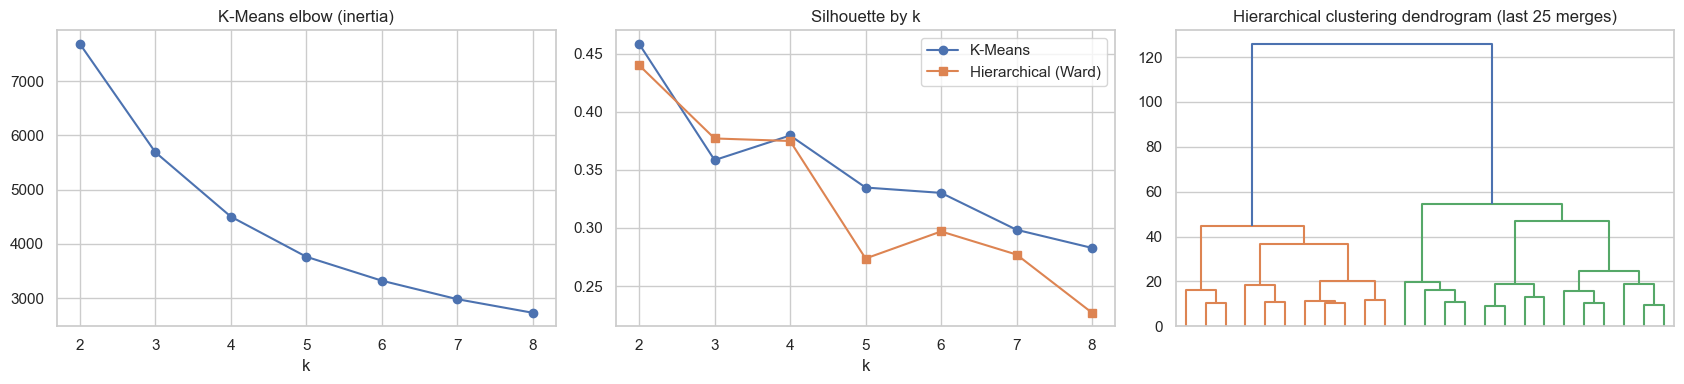

Best silhouette over all k (K-Means): 2
Chosen k (best silhouette between 3 and 6): 4
At k=4: K-Means silhouette 0.380 vs Hierarchical 0.375 -> higher: K-Means


In [11]:
prep = Pipeline([('log', FunctionTransformer(np.log1p)), ('scale', StandardScaler())])
Z = prep.fit_transform(ml_data[RFM_COLS])

rows = []
for k in range(2, 9):
    km_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    km_inertia = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z).inertia_
    hc_labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Z)
    rows.append({'k': k, 'KMeans_silhouette': silhouette_score(Z, km_labels),
                 'Hierarchical_silhouette': silhouette_score(Z, hc_labels),
                 'KMeans_inertia': km_inertia,
                 'Agreement_ARI': adjusted_rand_score(km_labels, hc_labels)})
k_table = pd.DataFrame(rows).set_index('k')
display(k_table.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(k_table.index, k_table['KMeans_inertia'], marker='o'); ax[0].set(title='K-Means elbow (inertia)', xlabel='k')
ax[1].plot(k_table.index, k_table['KMeans_silhouette'], marker='o', label='K-Means')
ax[1].plot(k_table.index, k_table['Hierarchical_silhouette'], marker='s', label='Hierarchical (Ward)')
ax[1].set(title='Silhouette by k', xlabel='k'); ax[1].legend()
dendrogram(linkage(Z, method='ward'), truncate_mode='lastp', p=25, no_labels=True, ax=ax[2])
ax[2].set_title('Hierarchical clustering dendrogram (last 25 merges)')
plt.tight_layout(); plt.show()

MIN_K, MAX_K = 3, 6
allowed = k_table.loc[MIN_K:MAX_K]
best_k = int(allowed['KMeans_silhouette'].idxmax())
print('Best silhouette over all k (K-Means):', int(k_table['KMeans_silhouette'].idxmax()))
print(f'Chosen k (best silhouette between {MIN_K} and {MAX_K}):', best_k)
better = 'K-Means' if k_table.loc[best_k, 'KMeans_silhouette'] >= k_table.loc[best_k, 'Hierarchical_silhouette'] else 'Hierarchical'
print(f'At k={best_k}: K-Means silhouette {k_table.loc[best_k, "KMeans_silhouette"]:.3f} vs Hierarchical {k_table.loc[best_k, "Hierarchical_silhouette"]:.3f} -> higher: {better}')

**Decision.** We deploy **K-Means**: its silhouette is shown next to the hierarchical result above, and it can assign a **new customer** to a segment with `.predict()`, which hierarchical clustering cannot do. Hierarchical clustering is kept as a cross-check (the ARI column shows how similar the two groupings are).

In [12]:
# Final segmentation pipeline: log1p -> scale -> KMeans (fitted on historical RFM only)
seg_pipeline = Pipeline([('log', FunctionTransformer(np.log1p)), ('scale', StandardScaler()),
                         ('kmeans', KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE))])
ml_data['Cluster'] = seg_pipeline.fit_predict(ml_data[RFM_COLS])

profile = ml_data.groupby('Cluster').agg(Customers=('Customer ID', 'count'),
                                         Recency=('Recency', 'mean'), Frequency=('Frequency', 'mean'),
                                         Monetary=('Monetary', 'mean'),
                                         Actual_Future90_Mean=(TARGET, 'mean'),
                                         Zero_Spend_Rate=(TARGET, lambda s: (s == 0).mean()))
profile['Share_of_customers'] = profile['Customers'] / profile['Customers'].sum()
display(profile.round(2))

,Customers,Recency,Frequency,Monetary,Actual_Future90_Mean,Zero_Spend_Rate,Share_of_customers
Cluster,,,,,,,
0,1588,196.07,5.16,"2,033.09",334.44,0.53,0.30
1,2121,341.89,1.42,342.18,162.66,0.80,0.40
2,672,31.67,2.74,758.38,390.39,0.44,0.13
3,875,30.66,19.38,"10,545.02","2,117.02",0.16,0.17


### 7.1 Segment names and marketing actions
Names are assigned by rule from each cluster's average R, F and M (best overall score = **Champions**, worst = **Lost / Inactive**, in between = **Loyal / Potential** or **At-Risk** depending on recency). They are descriptive labels, not ground truth: check them against the profile table above.

In [13]:
def name_segments(prof, median_recency):
    score = prof['Frequency'].rank() + prof['Monetary'].rank() + prof['Recency'].rank(ascending=False)
    order = score.sort_values(ascending=False).index.tolist()
    base = {}
    for pos, c in enumerate(order):
        if pos == 0:
            base[c] = 'Champions'
        elif pos == len(order) - 1:
            base[c] = 'Lost / Inactive'
        elif prof.loc[c, 'Recency'] > median_recency:
            base[c] = 'At-Risk'
        else:
            base[c] = 'Loyal / Potential'
    names, seen = {}, {}
    totals = pd.Series(base).value_counts()
    for c in order:
        b = base[c]
        if totals[b] > 1:
            seen[b] = seen.get(b, 0) + 1
            names[c] = f'{b} ({chr(64 + seen[b])})'
        else:
            names[c] = b
    return base, names

ACTIONS = {
    'Champions': 'Reward: loyalty perks, early access to new products, personalised recommendations.',
    'Loyal / Potential': 'Grow: cross-sell and upsell offers, encourage one more order per quarter.',
    'At-Risk': 'Win back: reminder emails with a time-limited offer before they churn.',
    'Lost / Inactive': 'Reactivate cheaply: low-cost email campaign; stop spending if no response.',
}
base_names, segment_names = name_segments(profile, ml_data['Recency'].median())
segment_info = profile.reset_index()
segment_info['Segment'] = segment_info['Cluster'].map(segment_names)
segment_info['Base_Segment'] = segment_info['Cluster'].map(base_names)
segment_info['Recommended_Action'] = segment_info['Base_Segment'].map(ACTIONS)
ml_data['Segment'] = ml_data['Cluster'].map(segment_names)
display(segment_info[['Cluster', 'Segment', 'Customers', 'Recency', 'Frequency', 'Monetary',
                      'Actual_Future90_Mean', 'Recommended_Action']].round(2))

,Cluster,Segment,Customers,Recency,Frequency,Monetary,Actual_Future90_Mean,Recommended_Action
0,0,At-Risk,1588,196.07,5.16,"2,033.09",334.44,Win back: reminder emails with a time-limited ...
1,1,Lost / Inactive,2121,341.89,1.42,342.18,162.66,Reactivate cheaply: low-cost email campaign; s...
2,2,Loyal / Potential,672,31.67,2.74,758.38,390.39,"Grow: cross-sell and upsell offers, encourage ..."
3,3,Champions,875,30.66,19.38,"10,545.02","2,117.02","Reward: loyalty perks, early access to new pro..."


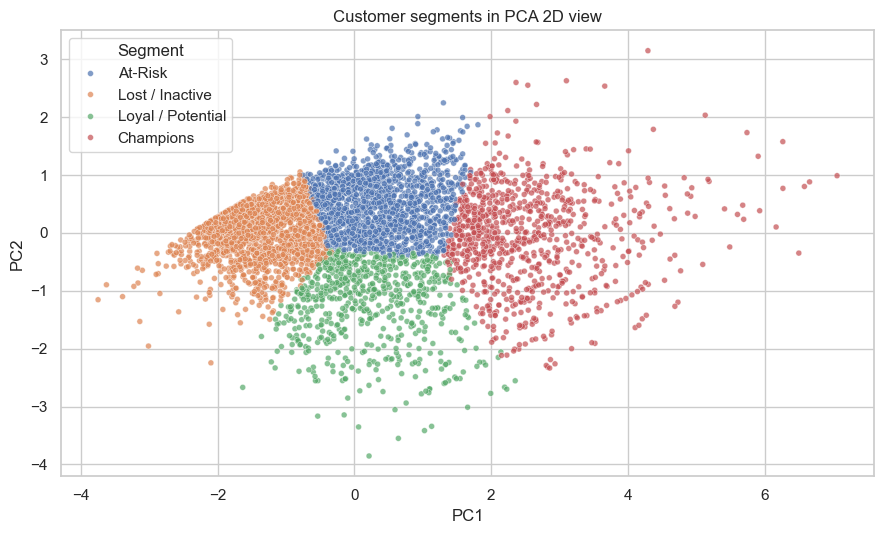

PCA explained variance (PC1, PC2): [0.761 0.189] | total: 0.95


In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(prep.transform(ml_data[RFM_COLS]))
plt.figure(figsize=(9, 5.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=ml_data['Segment'], s=18, alpha=.7)
plt.title('Customer segments in PCA 2D view'); plt.xlabel('PC1'); plt.ylabel('PC2')
plt.tight_layout(); plt.show()
print('PCA explained variance (PC1, PC2):', np.round(pca.explained_variance_ratio_, 3),
      '| total:', round(pca.explained_variance_ratio_.sum(), 3))

## 8. Train/test split and leakage-safe preprocessing
- We split customers **80/20 before fitting anything**. The 20% test set is touched only once, at the end.
- All preprocessing sits **inside a scikit-learn Pipeline**, so during cross-validation it is fitted on training folds only:
  1. `SimpleImputer(median)`: handles missing values (there are none now, but the pipeline stays safe for new data).
  2. `log1p`: reduces skew and the influence of extreme customers (outlier handling without deleting real customers).
  3. `StandardScaler`.
- The target is zero-heavy and long-tailed, so for each algorithm we also test a **log-target** version (`TransformedTargetRegressor`).
- A random customer split measures generalisation to *other customers at this cut-off*. It does not prove performance on future dates (see limitations).

In [15]:
X = ml_data[FEATURES]
y = ml_data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

def make_model(estimator, log_target=False):
    pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('log', FunctionTransformer(np.log1p)),
                     ('scale', StandardScaler()),
                     ('model', estimator)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return TransformedTargetRegressor(regressor=pipe)   # identity target

base_estimators = {
    'Ridge': Ridge(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}
candidates = {}
for name, est in base_estimators.items():
    candidates[name] = make_model(clone(est), log_target=False)
    candidates[f'{name} (log target)'] = make_model(clone(est), log_target=True)
baselines = {'Baseline: median': DummyRegressor(strategy='median'),
             'Baseline: mean': DummyRegressor(strategy='mean')}

Train: (4204, 7) | Test: (1052, 7)


## 9. Baselines, three algorithms and cross-validation
We compare **simple baselines** (always predict the median or the mean) with **three algorithms** (Ridge, Random Forest, Gradient Boosting), each with raw and log target, using 5-fold cross-validation on the **training set only**.

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

def cv_row(name, model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    return {'Model': name, 'CV_MAE': -res['test_MAE'].mean(), 'CV_MAE_SD': res['test_MAE'].std(),
            'CV_RMSE': -res['test_RMSE'].mean(), 'CV_R2': res['test_R2'].mean()}

cv_df = pd.DataFrame([cv_row(n, m) for n, m in {**baselines, **candidates}.items()]).sort_values('CV_MAE')
display(cv_df.round(2).reset_index(drop=True))

,Model,CV_MAE,CV_MAE_SD,CV_RMSE,CV_R2
0,Random Forest (log target),437.29,122.88,"2,846.45",0.46
1,Gradient Boosting (log target),452.11,111.73,"3,200.30",0.34
2,Ridge (log target),524.69,161.31,"3,816.30",-0.71
3,Random Forest,551.82,148.58,"3,606.24",0.05
4,Baseline: median,579.13,139.31,"4,019.73",-0.03
5,Gradient Boosting,589.69,179.02,"4,455.78",-0.72
6,Baseline: mean,786.96,112.85,"3,978.90",-0.00
7,Ridge,830.30,146.27,"3,757.95",0.12


## 10. Hyperparameter tuning (training data only)
Each candidate is tuned with `GridSearchCV` (5-fold, scoring = MAE) on the **training set**. The final model is chosen by **cross-validated MAE**, never by test results.

In [17]:
grids = {
    'Ridge': {'regressor__model__alpha': [0.1, 1, 10, 100, 500]},
    'Random Forest': {'regressor__model__max_depth': [5, 10], 'regressor__model__min_samples_leaf': [3, 10]},
    'Gradient Boosting': {'regressor__model__n_estimators': [100, 200],
                          'regressor__model__learning_rate': [0.03, 0.08],
                          'regressor__model__max_depth': [2, 3]},
}
tuned, rows = {}, []
for name, model in candidates.items():
    algo = name.replace(' (log target)', '')
    search = GridSearchCV(model, grids[algo], scoring='neg_mean_absolute_error', cv=cv, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    rows.append({'Model': name, 'Best_CV_MAE': -search.best_score_,
                 'Best_Params': {k.replace('regressor__model__', ''): v for k, v in search.best_params_.items()}})
tuning_df = pd.DataFrame(rows).sort_values('Best_CV_MAE').reset_index(drop=True)
display(tuning_df)

final_name = tuning_df.loc[0, 'Model']
final_model = tuned[final_name]
print('Selected by cross-validation (training data only):', final_name)

,Model,Best_CV_MAE,Best_Params
0,Random Forest (log target),442.48,"{'max_depth': 10, 'min_samples_leaf': 3}"
1,Gradient Boosting (log target),453.57,"{'learning_rate': 0.08, 'max_depth': 3, 'n_est..."
2,Ridge (log target),488.83,{'alpha': 500}
3,Random Forest,519.32,"{'max_depth': 10, 'min_samples_leaf': 3}"
4,Gradient Boosting,580.68,"{'learning_rate': 0.08, 'max_depth': 2, 'n_est..."
5,Ridge,766.98,{'alpha': 500}


Selected by cross-validation (training data only): Random Forest (log target)


## 11. Final evaluation on the untouched test set
We report **MAE, RMSE and R²** plus the business metric **Top-10% capture**. Predictions are clipped at 0 because spending cannot be negative; the same rule is used in the deployed app.

Besides the two dummy baselines we add a **business-rule baseline**: "next 90 days will look like the last 90 days" (`Spend_Last90d`). A model is only useful if it beats this simple rule.

In [18]:
def top_capture(y_true, y_pred, frac=0.10):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = max(1, int(round(len(y_true) * frac)))
    idx = np.argsort(-y_pred, kind='stable')[:n]
    return y_true[idx].sum() / y_true.sum()

def evaluate(name, pred):
    pred = np.maximum(np.asarray(pred), 0)
    return {'Model': name, 'Test_MAE': mean_absolute_error(y_test, pred),
            'Test_RMSE': np.sqrt(mean_squared_error(y_test, pred)),
            'Test_R2': r2_score(y_test, pred), 'Top10%_Capture': top_capture(y_test, pred)}

rows = []
for name, model in baselines.items():
    rows.append(evaluate(name, clone(model).fit(X_train, y_train).predict(X_test)))
rows.append(evaluate('Baseline: last-90-day spend', X_test['Spend_Last90d']))
for name, model in tuned.items():
    rows.append(evaluate(name + ('  <- selected' if name == final_name else ''), model.predict(X_test)))
test_results = pd.DataFrame(rows).sort_values('Test_MAE').reset_index(drop=True)
display(test_results.round(3))

oracle = top_capture(y_test, y_test)
print(f'Reference for Top-10% capture: random about 10% | perfect ranking {oracle:.1%}')
final_pred = np.maximum(final_model.predict(X_test), 0)

,Model,Test_MAE,Test_RMSE,Test_R2,Top10%_Capture
0,Gradient Boosting (log target),378.91,"1,209.70",0.63,0.61
1,Random Forest (log target) <- selected,392.79,"1,451.34",0.47,0.60
2,Baseline: last-90-day spend,399.47,"1,630.69",0.33,0.59
3,Gradient Boosting,440.45,"1,631.40",0.33,0.61
4,Random Forest,452.25,"1,982.41",0.01,0.61
5,Ridge (log target),453.82,"1,911.03",0.08,0.60
6,Baseline: median,528.91,"2,061.07",-0.07,0.10
7,Ridge,592.69,"1,598.94",0.36,0.58
8,Baseline: mean,741.68,"1,992.68",-0.00,0.10


Reference for Top-10% capture: random about 10% | perfect ranking 71.8%


## 12. Error analysis

,Customers,Avg_Actual,Avg_Predicted,MAE,Mean_Signed_Error
Group,,,,,
Zero spend,586,0.00,25.45,25.45,25.45
Q1 (lowest),117,142.18,47.28,130.13,-94.90
Q2,116,360.43,79.99,308.04,-280.44
Q3,116,740.08,207.69,599.63,-532.39
Q4 (highest),117,"3,522.37","1,825.32","2,374.24","-1,697.05"


Mean signed error (positive = over-prediction): -274.75
Median absolute error: 30.17
10 largest mistakes:


,Customer ID,Actual,Predicted,Error,Frequency,Monetary,Spend_Last90d
1580,14156,"18,321.29","45,753.81","27,432.52",131,"284,748.59","53,538.44"
4461,17389,"22,329.60","5,183.87","-17,145.73",52,"34,885.73","4,376.54"
3243,16029,"26,720.70","10,381.94","-16,338.76",95,"82,900.17","17,383.88"
3829,16684,"32,770.06","19,949.72","-12,820.34",45,"114,372.71","8,807.56"
652,13098,"13,712.98","2,401.24","-11,311.74",18,"15,169.46","7,434.49"
2053,14680,"3,331.55","10,654.88","7,323.33",56,"52,356.95","10,888.68"
279,12678,"8,857.20","1,714.44","-7,142.76",12,"23,737.98","2,100.90"
80,12433,"6,980.64",825.31,"-6,155.33",6,"9,813.50","2,608.11"
3231,16013,"13,721.26","8,210.53","-5,510.73",72,"42,357.18","10,608.02"
4475,17404,"10,887.52","5,444.26","-5,443.26",17,"36,750.60","7,040.68"


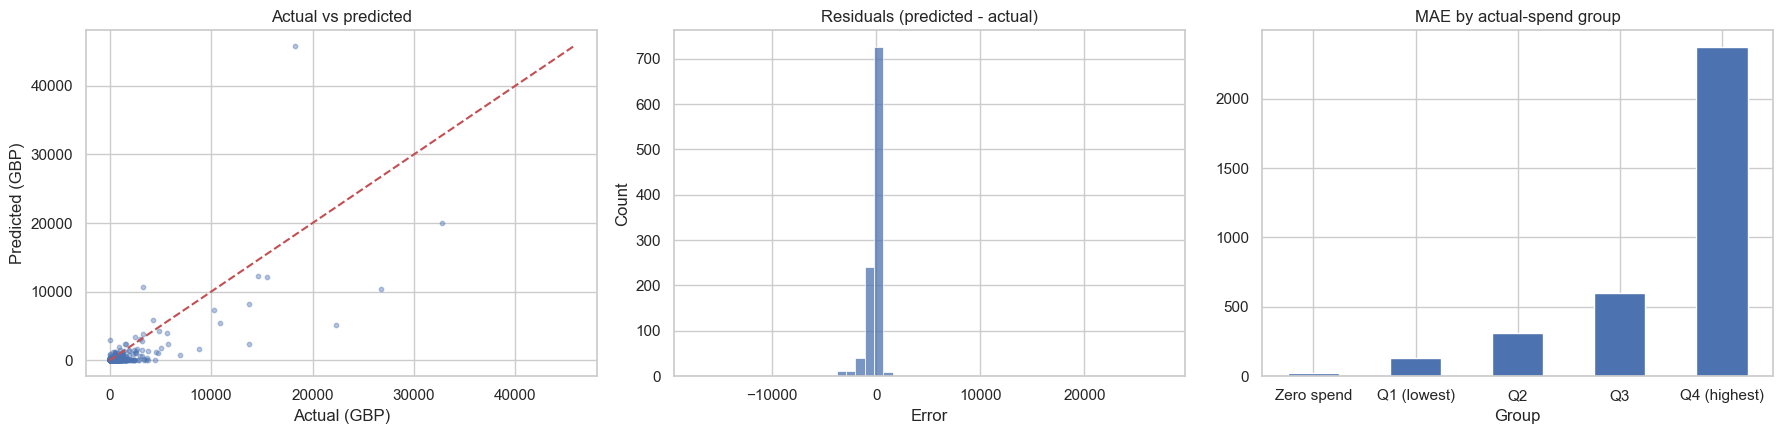

In [19]:
err = X_test.copy()
err['Customer ID'] = ml_data.loc[X_test.index, 'Customer ID']
err['Actual'] = y_test
err['Predicted'] = final_pred
err['Error'] = err['Predicted'] - err['Actual']
err['AbsError'] = err['Error'].abs()

err['Group'] = 'Zero spend'
pos = err['Actual'] > 0
err.loc[pos, 'Group'] = pd.qcut(err.loc[pos, 'Actual'], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)']).astype(str)
group_order = ['Zero spend', 'Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)']
summary = err.groupby('Group').agg(Customers=('Actual', 'size'), Avg_Actual=('Actual', 'mean'),
                                   Avg_Predicted=('Predicted', 'mean'), MAE=('AbsError', 'mean'),
                                   Mean_Signed_Error=('Error', 'mean')).reindex(group_order)
display(summary.round(2))
print('Mean signed error (positive = over-prediction):', round(err['Error'].mean(), 2))
print('Median absolute error:', round(err['AbsError'].median(), 2))
print('10 largest mistakes:')
display(err.nlargest(10, 'AbsError')[['Customer ID', 'Actual', 'Predicted', 'Error', 'Frequency', 'Monetary', 'Spend_Last90d']].round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
lim = max(err['Actual'].max(), err['Predicted'].max())
ax[0].scatter(err['Actual'], err['Predicted'], s=10, alpha=.4); ax[0].plot([0, lim], [0, lim], 'r--')
ax[0].set(xlabel='Actual (GBP)', ylabel='Predicted (GBP)', title='Actual vs predicted')
sns.histplot(err['Error'], bins=50, ax=ax[1]); ax[1].set_title('Residuals (predicted - actual)')
summary['MAE'].plot(kind='bar', ax=ax[2], title='MAE by actual-spend group'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

### 12.1 Which features matter? (permutation importance on the test set)

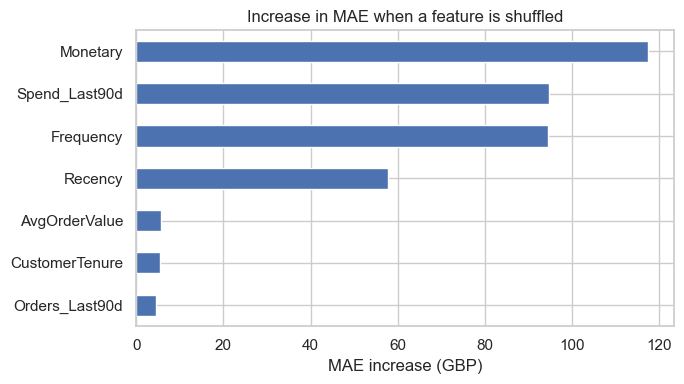

In [20]:
perm = permutation_importance(final_model, X_test, y_test, scoring='neg_mean_absolute_error',
                              n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
importance.plot(kind='barh', figsize=(7, 4), title='Increase in MAE when a feature is shuffled')
plt.xlabel('MAE increase (GBP)'); plt.tight_layout(); plt.show()

## 13. Business insight, revenue at stake and limitations
The score table below applies the **final segmentation pipeline and the final model** to every customer at the **last date in the data**, so the predictions refer to the real "next 90 days". Revenue at stake = sum of predicted next-90-day spend per segment.

,Customers,Predicted_90d_Revenue,Avg_Predicted_per_Customer,Last_90d_Revenue,Share_of_Predicted_Revenue,Expected_Change_vs_Last_90d
Segment,,,,,,
Champions,1194,"1,500,540.18","1,256.73","2,575,751.06",0.93,"-1,075,210.88"
Loyal / Potential,1258,"67,627.06",53.76,"577,470.71",0.04,"-509,843.65"
At-Risk,1405,"48,141.12",34.26,"201,879.91",0.03,"-153,738.79"
Lost / Inactive,1995,"5,779.05",2.90,"22,641.35",0.00,"-16,862.30"


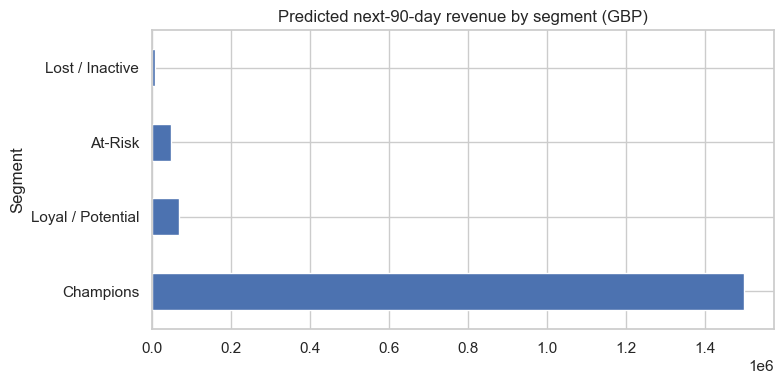

In [21]:
as_of_final = df_clean['InvoiceDate'].max() + pd.Timedelta(seconds=1)
score_df = build_features(df_clean, as_of_final)
score_df['Cluster'] = seg_pipeline.predict(score_df[RFM_COLS])
score_df['Segment'] = score_df['Cluster'].map(segment_names)
score_df['Recommended_Action'] = score_df['Cluster'].map(segment_info.set_index('Cluster')['Recommended_Action'])
score_df['Predicted_Next90d_Spend'] = np.maximum(final_model.predict(score_df[FEATURES]), 0)
score_df['Country'] = score_df['Customer ID'].map(df_clean.groupby('Customer ID')['Country'].agg(lambda s: s.mode().iloc[0]))

stake = score_df.groupby('Segment').agg(Customers=('Customer ID', 'count'),
                                       Predicted_90d_Revenue=('Predicted_Next90d_Spend', 'sum'),
                                       Avg_Predicted_per_Customer=('Predicted_Next90d_Spend', 'mean'),
                                       Last_90d_Revenue=('Spend_Last90d', 'sum'))
stake['Share_of_Predicted_Revenue'] = stake['Predicted_90d_Revenue'] / stake['Predicted_90d_Revenue'].sum()
stake['Expected_Change_vs_Last_90d'] = stake['Predicted_90d_Revenue'] - stake['Last_90d_Revenue']
stake = stake.sort_values('Predicted_90d_Revenue', ascending=False)
display(stake.round(2))
stake['Predicted_90d_Revenue'].plot(kind='barh', figsize=(8, 4), title='Predicted next-90-day revenue by segment (GBP)')
plt.tight_layout(); plt.show()

In [22]:
best_row = test_results[test_results['Model'].str.contains('selected')].iloc[0]
base_row = test_results[test_results['Model'] == 'Baseline: median'].iloc[0]
rule_row = test_results[test_results['Model'] == 'Baseline: last-90-day spend'].iloc[0]
top_seg = stake.index[0]
print('KEY TAKEAWAYS (computed from this run)')
print(f'- Selected model: {final_name}. Test MAE = GBP {best_row.Test_MAE:,.0f} vs GBP {base_row.Test_MAE:,.0f} for the median baseline '
      f'({1 - best_row.Test_MAE / base_row.Test_MAE:.0%} lower) and GBP {rule_row.Test_MAE:,.0f} for the "same as last 90 days" rule.')
print(f'- Test R2 = {best_row.Test_R2:.2f}, RMSE = GBP {best_row.Test_RMSE:,.0f}.')
print(f'- The 10% of customers ranked highest by the model hold {best_row["Top10%_Capture"]:.0%} of the actual next-90-day revenue (random targeting: about 10%).')
print(f'- Largest predicted revenue pool: {top_seg} ({stake.loc[top_seg, "Share_of_Predicted_Revenue"]:.0%} of predicted revenue from {stake.loc[top_seg, "Customers"]:,.0f} customers).')
worst = summary['MAE'].idxmax()
print(f'- Error is highest for the "{worst}" group (MAE GBP {summary.loc[worst, "MAE"]:,.0f}); see the error analysis for the largest misses.')

KEY TAKEAWAYS (computed from this run)
- Selected model: Random Forest (log target). Test MAE = GBP 393 vs GBP 529 for the median baseline (26% lower) and GBP 399 for the "same as last 90 days" rule.
- Test R2 = 0.47, RMSE = GBP 1,451.
- The 10% of customers ranked highest by the model hold 60% of the actual next-90-day revenue (random targeting: about 10%).
- Largest predicted revenue pool: Champions (93% of predicted revenue from 1,194 customers).
- Error is highest for the "Q4 (highest)" group (MAE GBP 2,374); see the error analysis for the largest misses.


### Recommendations
- **Champions:** protect with loyalty rewards and early access (check the revenue-at-stake table for how much of the predicted revenue they carry).
- **Loyal / Potential:** push one extra order per quarter with cross-sell offers.
- **At-Risk:** send time-limited win-back offers before they become inactive.
- **Lost / Inactive:** use only low-cost reactivation emails; stop if there is no response.
- **Use predicted spend to prioritise outreach:** contact a customer only when predicted value is larger than the cost of the campaign. Predictions are estimates, not guaranteed revenue.

### Limitations
- One historical period and **one 90-day cut-off** (no rolling cut-offs); the test set is a random customer split, so it does not prove performance on future dates.
- Retail data from 2009 to 2011, strong **seasonality**, and mostly UK customers.
- The target is zero-heavy and long-tailed: a few wholesale customers dominate the errors.
- No marketing-cost or campaign-response data, so no causal claim that the recommended actions increase revenue (an A/B test is needed).
- New customers without history cannot be scored.
- Scoring at the final date uses customers with longer history than most training customers, so predictions for very old customers are extrapolations.
- Segment names are heuristic labels based on RFM averages.

## 14. Save the final pipeline for the Streamlit app
Everything the app needs is saved in the folder `streamlit_app/`: the **final model pipeline** (`joblib`), the **segmentation pipeline**, the scored customer table, the segment profiles, the results table, and a `requirements.txt` with the exact library versions used here (to avoid pickle version errors when deploying).

In [25]:
OUT = 'streamlit_app'
os.makedirs(OUT, exist_ok=True)

joblib.dump(final_model, f'{OUT}/customer_spending_model.pkl')
joblib.dump(seg_pipeline, f'{OUT}/customer_segmentation_pipeline.pkl')
score_df.to_csv(f'{OUT}/customer_scoring_table.csv', index=False)
segment_info.to_csv(f'{OUT}/segment_info.csv', index=False)
stake.reset_index().to_csv(f'{OUT}/revenue_at_stake.csv', index=False)
test_results.to_csv(f'{OUT}/model_results.csv', index=False)

config = {'features': FEATURES, 'rfm_cols': RFM_COLS, 'selected_model': final_name,
          'training_cutoff': str(cutoff_date), 'scored_as_of': str(as_of_final),
          'test_mae': float(best_row.Test_MAE), 'test_rmse': float(best_row.Test_RMSE), 'test_r2': float(best_row.Test_R2)}
with open(f'{OUT}/app_config.json', 'w') as f:
    json.dump(config, f, indent=2)

import pandas, numpy, scipy, joblib as _jl
with open(f'{OUT}/requirements.txt', 'w') as f:
    f.write(f'streamlit\npandas=={pandas.__version__}\nnumpy=={numpy.__version__}\n'
            f'scikit-learn=={sklearn.__version__}\nscipy=={scipy.__version__}\njoblib=={_jl.__version__}\n')
print('Saved:', sorted(os.listdir(OUT)))

Saved: ['app_config.json', 'customer_scoring_table.csv', 'customer_segmentation_pipeline.pkl', 'customer_spending_model.pkl', 'model_results.csv', 'requirements.txt', 'revenue_at_stake.csv', 'segment_info.csv']


In [26]:
# Deployment sanity check: reload the saved files and confirm they reproduce the notebook predictions
m = joblib.load(f'{OUT}/customer_spending_model.pkl')
s = joblib.load(f'{OUT}/customer_segmentation_pipeline.pkl')
sample = score_df.sample(5, random_state=1)
assert np.allclose(np.maximum(m.predict(sample[FEATURES]), 0), sample['Predicted_Next90d_Spend'])
assert (s.predict(sample[RFM_COLS]) == sample['Cluster']).all()
print('Saved model and segmentation pipeline reproduce the notebook results.')
display(sample[['Customer ID', 'Segment', 'Predicted_Next90d_Spend', 'Recommended_Action']].round(2))

Saved model and segmentation pipeline reproduce the notebook results.


,Customer ID,Segment,Predicted_Next90d_Spend,Recommended_Action
3973,16382,Lost / Inactive,0.19,Reactivate cheaply: low-cost email campaign; s...
1403,13778,At-Risk,11.18,Win back: reminder emails with a time-limited ...
4845,17266,Loyal / Potential,7.23,"Grow: cross-sell and upsell offers, encourage ..."
1884,14263,Lost / Inactive,2.33,Reactivate cheaply: low-cost email campaign; s...
3466,15868,Lost / Inactive,0.14,Reactivate cheaply: low-cost email campaign; s...


## 15. Reproducibility and next steps
- Run **Kernel > Restart & Run All**. Required libraries: `pandas numpy matplotlib seaborn scikit-learn scipy joblib openpyxl`.
- Copy `app.py` into the `streamlit_app/` folder, test it locally with `streamlit run app.py`, then deploy that folder on Streamlit Community Cloud.
- Every number in the README, slides, CV bullet and LinkedIn post must be copied from the outputs of this notebook.
- **Next steps:** rolling cut-offs for time-based validation, richer features (product categories, order gaps), and A/B tests of the marketing actions.

In [27]:
import os
print(os.path.abspath("streamlit_app"))

C:\Users\Lenovo\streamlit_app
